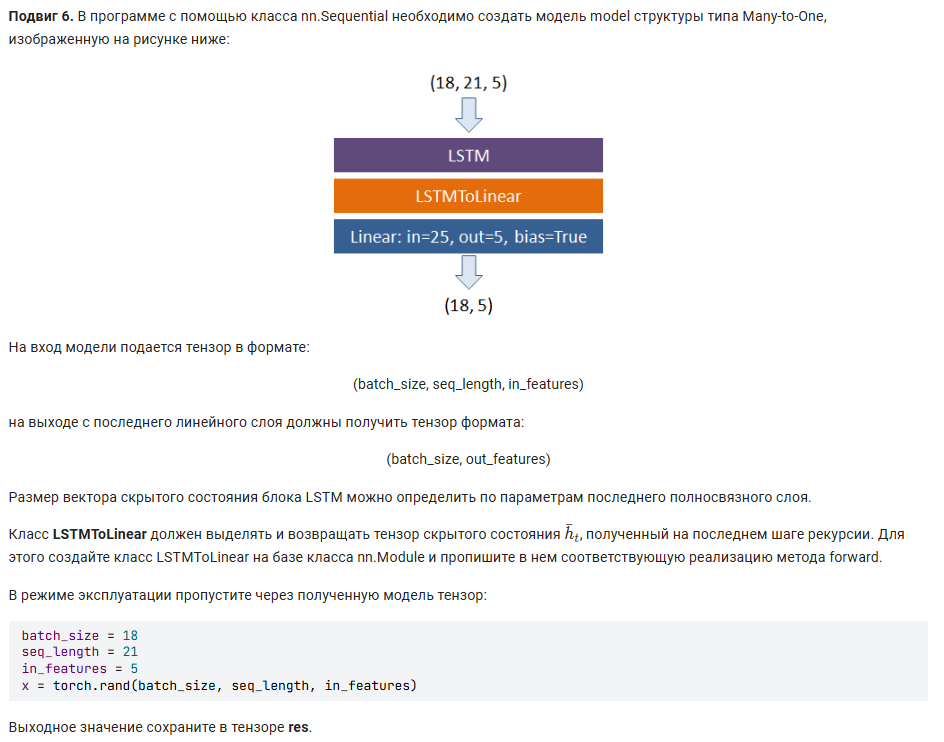

In [5]:
import torch
import torch.nn as nn

# здесь объявляйте класс LSTMToLinear
class LSTMToLinear(nn.Module):
    def __init__(self):
        super().__init__()
        
    def forward(self, x):
        y, (h, c) = x
        return h

# тензор x в программе не менять
batch_size = 18
seq_length = 21
in_features = 5
x = torch.rand(batch_size, seq_length, in_features)

# здесь продолжайте программу
model = nn.Sequential(
    nn.LSTM(input_size=5, hidden_size=25, batch_first=True),
    LSTMToLinear(),
    nn.Linear(25, 5)
)

model.eval()
res = model(x)
res

torch.Size([1, 18, 25])


tensor([[[-0.0998,  0.1365,  0.2093,  0.0569,  0.0182],
         [-0.1180,  0.1096,  0.2243,  0.0417, -0.0134],
         [-0.0846,  0.1343,  0.2355,  0.0468,  0.0108],
         [-0.0932,  0.1295,  0.2338,  0.0509,  0.0062],
         [-0.0986,  0.1289,  0.2358,  0.0542,  0.0020],
         [-0.1176,  0.1145,  0.2028,  0.0513,  0.0079],
         [-0.1010,  0.1145,  0.2490,  0.0334, -0.0076],
         [-0.0900,  0.1308,  0.2443,  0.0604,  0.0157],
         [-0.0938,  0.1287,  0.2442,  0.0510,  0.0038],
         [-0.1023,  0.1241,  0.2131,  0.0395, -0.0058],
         [-0.0927,  0.1358,  0.2214,  0.0648,  0.0146],
         [-0.1103,  0.1093,  0.2486,  0.0325, -0.0156],
         [-0.0931,  0.1366,  0.2289,  0.0546,  0.0021],
         [-0.1121,  0.1043,  0.2339,  0.0173, -0.0354],
         [-0.0951,  0.1133,  0.2586,  0.0226, -0.0309],
         [-0.0980,  0.1275,  0.2230,  0.0530,  0.0041],
         [-0.1113,  0.1118,  0.2289,  0.0308, -0.0267],
         [-0.1032,  0.1172,  0.2461,  0.0425, -0

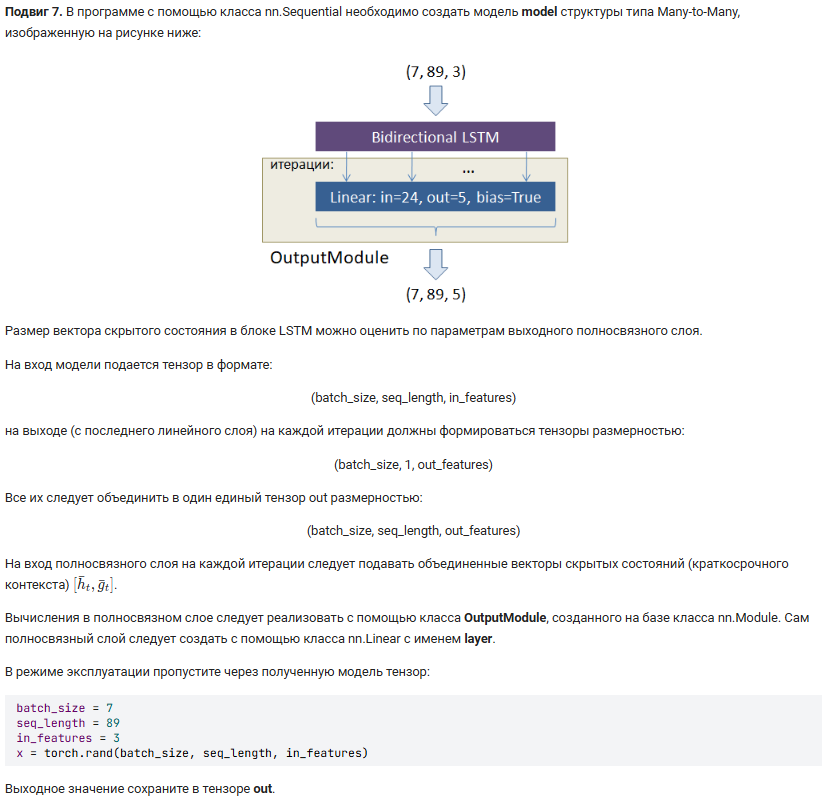

In [19]:
import torch
import torch.nn as nn

# здесь объявляйте класс OutputModule
class OutputModule(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer = nn.Linear(24, 5)

    def forward(self, x):
        y, (_, _) = x
        seq_length = y.shape[1]
        res = []
        for i in range(seq_length):
            res.append(self.layer(y[:, i, :].squeeze(1)))

        res = torch.stack(res, dim=1)

        return res

# тензор x в программе не менять
batch_size = 7
seq_length = 89
in_features = 3
x = torch.rand(batch_size, seq_length, in_features)

# здесь продолжайте программу
model = nn.Sequential(
    nn.LSTM(input_size=3, hidden_size=12, bidirectional=True, batch_first=True),
    OutputModule()
)
model.eval()
out = model(x)
out.shape

torch.Size([7, 89, 5])

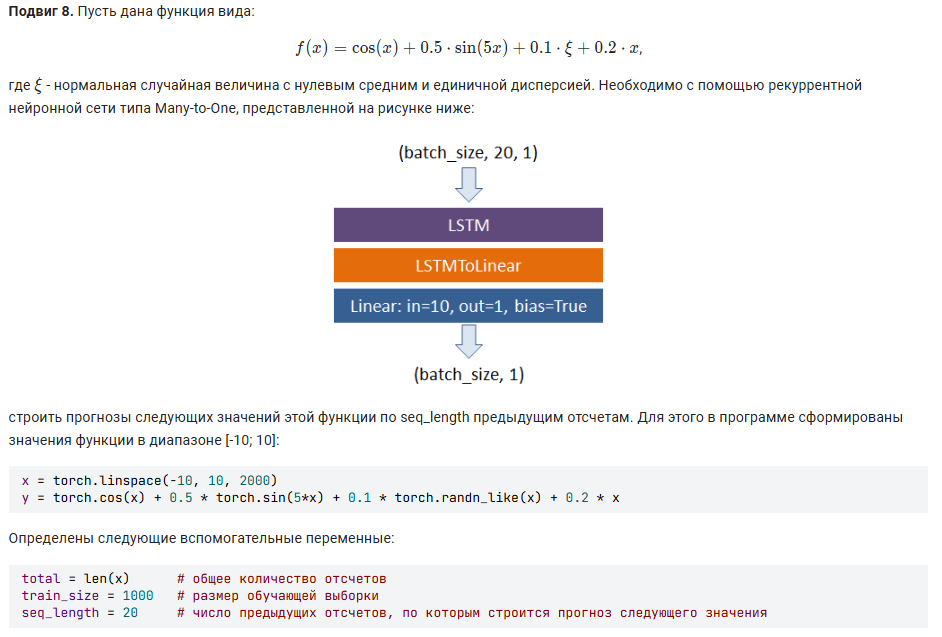

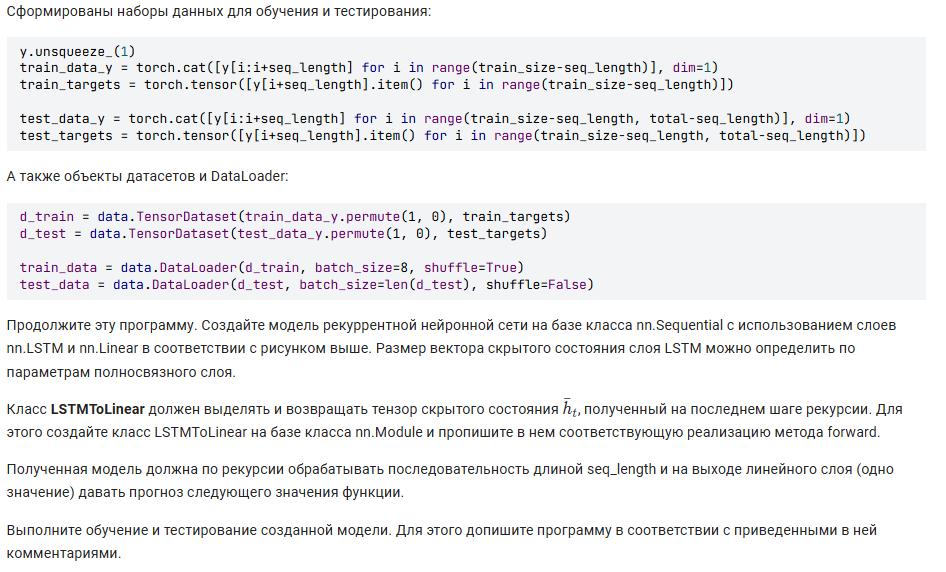

In [80]:
import torch
import torch.nn as nn
import torch.utils.data as data
import torch.optim as optim

from tqdm import tqdm

# здесь объявляйте класс LSTMToLinear
class LSTMToLinear(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        y, (h, c) = x
        h = h.squeeze(0)
        c = c.squeeze(0)
        # print(h.shape, c.shape)
        # return c
        return h # [batch_size, hidden_size]
        
    
model = nn.Sequential(
    nn.LSTM(input_size=1, hidden_size=10, bidirectional=False, batch_first=True),
    LSTMToLinear(),
    nn.Linear(10, 1)
) # здесь описывайте модель с помощью класса Sequential

x = torch.linspace(-10, 10, 2000)
y = torch.cos(x) + 0.5 * torch.sin(5*x) + 0.1 * torch.randn_like(x) + 0.2 * x

total = len(x)      # общее количество отсчетов
train_size = 1000   # размер обучающей выборки
seq_length = 20     # число предыдущих отсчетов, по которым строится прогноз следующего значения

y.unsqueeze_(1)
train_data_y = torch.cat([y[i:i+seq_length] for i in range(train_size-seq_length)], dim=1)
train_targets = torch.tensor([y[i+seq_length].item() for i in range(train_size-seq_length)])

test_data_y = torch.cat([y[i:i+seq_length] for i in range(train_size-seq_length, total-seq_length)], dim=1)
test_targets = torch.tensor([y[i+seq_length].item() for i in range(train_size-seq_length, total-seq_length)])

d_train = data.TensorDataset(train_data_y.permute(1, 0), train_targets)
d_test = data.TensorDataset(test_data_y.permute(1, 0), test_targets)

train_data = data.DataLoader(d_train, batch_size=8, shuffle=True)
test_data = data.DataLoader(d_test, batch_size=len(d_test), shuffle=False)

optimizer = optim.RMSprop(model.parameters(), lr=0.01) # оптимизатор RMSprop с шагом обучения 0.01
loss_func = nn.MSELoss() # функция потерь - средний квадрат ошибок

epochs = 50 # число эпох
# переведите модель в режим обучения
model.train()

for _e in tqdm(range(epochs), leave=True):
    for x_train, y_train in train_data:
        x_train = x_train.unsqueeze(-1) # [batch_size, hidden_size, input_size]
        # print(x_train.shape)
        predict = model(x_train).squeeze(1) # вычислите прогноз модели для x_train
        # print(predict.shape, y_train.shape) # [batch_size]
        loss = loss_func(predict, y_train) # вычислите потери для predict и y_train
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        # выполните один шаг обучения (градиентного спуска)


# переведите модель в режим эксплуатации
d, t = next(iter(test_data))

model.eval()
# с использованием менеджера torch.no_grad вычислите прогнозы для выборки d
with torch.no_grad():
    predict = model(d.unsqueeze(-1)).squeeze(1)
# результат сохраните в тензоре predict
Q = loss_func(predict, t).item() # вычислите потери с помощью loss_func для predict и t; значение Q сохраните в виде вещественного числа
Q

100%|██████████| 50/50 [00:11<00:00,  4.33it/s]


0.28815758228302

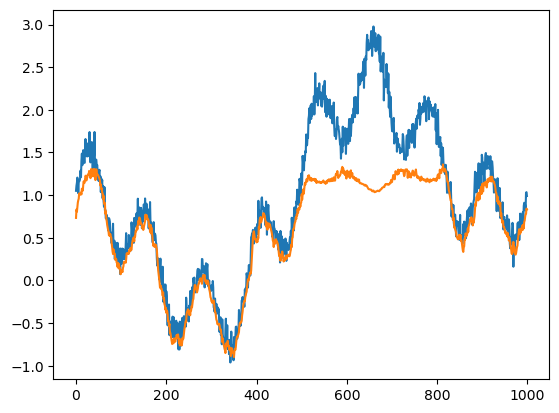

In [81]:
import matplotlib.pyplot as plt
plt.plot(t)
plt.plot(predict)